In [1]:
import os
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv())
src_path = os.environ.get('PROJECT_SRC')
os.chdir(src_path)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import cop
import FES_scaling_factor
import geopandas as gpd
import FES_shapefile_LAs_matching
import LA_overlaps_within_gird_squares
import heat_tech_distribution
from tech_half_hourly_profile import scaling_half_hourly_profiles_grid_sqs, base_heat_pattern_per_technology
from Grid_squares_heat_tech_demand import calculate_heat_demand_for_grid_squares
import elec_demand as ed


In [3]:

weather_year = 2012
future_year = 2050
FES_year = '2022'
FES_scenario = 'LW'
grid_id = '-3.5_56.0'

In [4]:

LA_shapefile = gpd.read_file(r'data\LA_UK\new_version\UK_LAs_Boundaries_files\LAs_shapefile_2021\LAD_DEC_2021_GB_BFC.shp')
grid_squares =  gpd.read_file(r'data\LA_UK\new_version\data_call\UK_Atlite_Grid_sq.gpkg')

In [5]:
air_temp_df = pd.read_csv(f'data/LA_UK/new_version/air_temp_new/air_temp_{weather_year}.csv', index_col=0)
grid_sqs = [str(gid).strip() for gid in air_temp_df.columns]

In [6]:
df_ASHP = cop.day_cop_for_year_grid_sq('ASHP', 'very good', future_year=future_year, weather_year=weather_year)
df_GSHP = cop.day_cop_for_year_grid_sq('GSHP', 'very good', future_year=future_year, weather_year=weather_year)

In [7]:
LA_overlaps = LA_overlaps_within_gird_squares.calc_LA_overlap_within_grid_square(grid_squares,
                                                                                LA_shapefile,
                                                                                weather_year)
LA_overlaps

,grid_x,grid_y,LA_Code,Local_Authority,long,lat,overlap_area,LA_area,overlap_percentage
Grid_ID,,,,,,,,,
-6.5_50.0,-6.50,50.00,E06000053,Isles of Scilly,-6.30217,49.9233,7.878469e+04,1.625142e+07,0.484787
-6.25_50.0,-6.25,50.00,E06000053,Isles of Scilly,-6.30217,49.9233,1.617263e+07,1.625142e+07,99.515213
-5.75_50.0,-5.75,50.00,E06000052,Cornwall,-4.64254,50.4502,5.036570e+07,3.548939e+09,1.419176
-5.5_50.0,-5.50,50.00,E06000052,Cornwall,-4.64254,50.4502,6.136620e+07,3.548939e+09,1.729142
-5.25_50.0,-5.25,50.00,E06000052,Cornwall,-4.64254,50.4502,1.940778e+08,3.548939e+09,5.468616
...,...,...,...,...,...,...,...,...,...
-1.0_60.5,-1.00,60.50,S12000027,Shetland Islands,-1.37344,60.5050,1.122228e+08,1.468514e+09,7.641929
-0.75_60.5,-0.75,60.50,S12000027,Shetland Islands,-1.37344,60.5050,2.375825e+07,1.468514e+09,1.617842
-1.25_60.75,-1.25,60.75,S12000027,Shetland Islands,-1.37344,60.5050,1.130301e+07,1.468514e+09,0.769690


In [8]:
df_merged = heat_tech_distribution.merge_shapefile_FES_heating_tech_file(grid_squares, 
                                                                             LA_overlaps, 
                                                                             future_year,
                                                                             FES_year, 
                                                                             FES_scenario,
                                                                             weather_year)
df_merged 

Sample FES LAs: ['Aberdeen City', 'Aberdeenshire', 'Adur', 'Allerdale', 'Amber Valley', 'Angus', 'Argyll And Bute', 'Arun', 'Ashfield', 'Ashford']
Sample Grid LAs: ['Isles Of Scilly' 'Cornwall' 'Plymouth' 'South Hams' 'Torbay'
 'West Devon' 'Teignbridge' 'East Devon' 'Dorset' 'Isle Of Wight']


,grid_x,grid_y,LA_Code,Local_Authority,long,lat,overlap_area,LA_area,overlap_percentage,CODE_x,...,stock_proportion GSHP,stock_proportion Gas boiler,stock_proportion Oil boiler,stock_proportion TotalHPs,stock_proportion BioLPG boiler,stock_proportion Biomass boiler,stock_proportion Hybrid (ASHP + BioLPG boiler),stock_proportion Hybrid (ASHP + Electric resistive),stock_proportion Hybrid (ASHP + Hydrogen boiler),stock_proportion Hydrogen boiler
Grid_ID,,,,,,,,,,,,,,,,,,,,,
-6.5_50.0,-6.50,50.00,E06000053,Isles Of Scilly,-6.30217,49.9233,7.878469e+04,1.625142e+07,0.484787,E06000053,...,0.174507,7.219101e-08,2.315929e-11,0.521814,0.054517,0.016251,0.021622,0.122718,0.026322,0.049381
-6.25_50.0,-6.25,50.00,E06000053,Isles Of Scilly,-6.30217,49.9233,1.617263e+07,1.625142e+07,99.515213,E06000053,...,0.174507,7.219101e-08,2.315929e-11,0.521814,0.054517,0.016251,0.021622,0.122718,0.026322,0.049381
-5.75_50.0,-5.75,50.00,E06000052,Cornwall,-4.64254,50.4502,5.036570e+07,3.548939e+09,1.419176,E06000052,...,0.219215,1.009156e-07,3.539338e-11,0.616544,0.047273,0.022603,0.021456,0.148074,0.033487,0.046251
-5.5_50.0,-5.50,50.00,E06000052,Cornwall,-4.64254,50.4502,6.136620e+07,3.548939e+09,1.729142,E06000052,...,0.219215,1.009156e-07,3.539338e-11,0.616544,0.047273,0.022603,0.021456,0.148074,0.033487,0.046251
-5.25_50.0,-5.25,50.00,E06000052,Cornwall,-4.64254,50.4502,1.940778e+08,3.548939e+09,5.468616,E06000052,...,0.219215,1.009156e-07,3.539338e-11,0.616544,0.047273,0.022603,0.021456,0.148074,0.033487,0.046251
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
-1.0_60.5,-1.00,60.50,S12000027,Shetland Islands,-1.37344,60.5050,1.122228e+08,1.468514e+09,7.641929,S12000027,...,0.062459,0.000000e+00,0.000000e+00,0.348337,0.040937,0.008607,0.024305,0.080819,0.002302,0.007714
-0.75_60.5,-0.75,60.50,S12000027,Shetland Islands,-1.37344,60.5050,2.375825e+07,1.468514e+09,1.617842,S12000027,...,0.062459,0.000000e+00,0.000000e+00,0.348337,0.040937,0.008607,0.024305,0.080819,0.002302,0.007714
-1.25_60.75,-1.25,60.75,S12000027,Shetland Islands,-1.37344,60.5050,1.130301e+07,1.468514e+09,0.769690,S12000027,...,0.062459,0.000000e+00,0.000000e+00,0.348337,0.040937,0.008607,0.024305,0.080819,0.002302,0.007714


In [9]:
FES_scaling = FES_scaling_factor.FES_scaling_factor_calc(future_year, FES_year, FES_scenario) 
base_pattern = base_heat_pattern_per_technology()

In [10]:
total_dwellings = calculate_heat_demand_for_grid_squares(LA_overlaps, weather_year, future_year, FES_year, FES_scenario, LA_shapefile, grid_squares)


Sample FES LAs: ['Aberdeen City', 'Aberdeenshire', 'Adur', 'Allerdale', 'Amber Valley', 'Angus', 'Argyll And Bute', 'Arun', 'Ashfield', 'Ashford']
Sample Grid LAs: ['Isles Of Scilly' 'Cornwall' 'Plymouth' 'South Hams' 'Torbay'
 'West Devon' 'Teignbridge' 'East Devon' 'Dorset' 'Isle Of Wight']
Sample FES LAs: ['Aberdeen City', 'Aberdeenshire', 'Adur', 'Allerdale', 'Amber Valley', 'Angus', 'Argyll And Bute', 'Arun', 'Ashfield', 'Ashford']
Sample Grid LAs: ['Isles Of Scilly' 'Cornwall' 'Plymouth' 'South Hams' 'Torbay'
 'West Devon' 'Teignbridge' 'East Devon' 'Dorset' 'Isle Of Wight']


In [11]:
pattern_profile_path = "data/LA_UK/new_version/outputs/heat_demand_profiles_patterns"
scaled_profiles_dict = scaling_half_hourly_profiles_grid_sqs(
pattern_profile_path,
total_dwellings,
weather_year,
future_year,
FES_year,
FES_scenario,
output_dir=None)

✅ All heating profiles already exist. Loading from disk.


In [12]:
FES_scaling

0.4147159132596685

In [13]:
scaled_profiles_dict

{'-0.25_50.75':                             ASHP          GSHP  Gas boiler  Electric storage  \
 2050-01-01 00:00:00  4722.659598   6146.772066    0.011456       1695.809057   
 2050-01-01 00:30:00  4927.956198   6465.044055    0.011373       1803.450148   
 2050-01-01 01:00:00  5304.301957   6985.828341    0.011938       1959.223434   
 2050-01-01 01:30:00  5552.054983   7323.549125    0.012341       2057.918743   
 2050-01-01 02:00:00  6146.193464   8056.923907    0.014054       2241.598979   
 ...                          ...           ...         ...               ...   
 2050-12-31 21:30:00  9446.337463  11284.853226    0.033375       2703.223657   
 2050-12-31 22:00:00  8344.753005  10202.956041    0.027198       2550.013208   
 2050-12-31 22:30:00  7262.180159   9135.405905    0.021097       2395.190017   
 2050-12-31 23:00:00  6485.205420   8381.167312    0.016556       2291.571372   
 2050-12-31 23:30:00  6118.491574   8052.473736    0.014102       2260.794887   
 
           

In [14]:
folder = f"data/LA_UK/new_version/outputs/heating_profiles/{FES_year}_{FES_scenario}_{future_year}"
scaled_profiles_dict = {}

for grid_id in grid_sqs:
    file_name = f"half_hourly_heat_profile_{grid_id}_{FES_year}_{FES_scenario}_{future_year}.csv"
    file_path = os.path.join(folder, file_name)

    if not os.path.exists(file_path):
        print(f"⚠️ File not found: {file_path}")
        continue

    hd_df = pd.read_csv(file_path, index_col=0)
    hd_df.index = pd.to_datetime(hd_df.index)
    scaled_profiles_dict[grid_id] = hd_df
scaled_profiles_dict

{'-0.25_50.75':                             ASHP          GSHP  Gas boiler  Electric storage  \
 2050-01-01 00:00:00  4722.659598   6146.772066    0.011456       1695.809057   
 2050-01-01 00:30:00  4927.956198   6465.044055    0.011373       1803.450148   
 2050-01-01 01:00:00  5304.301957   6985.828341    0.011938       1959.223434   
 2050-01-01 01:30:00  5552.054983   7323.549125    0.012341       2057.918743   
 2050-01-01 02:00:00  6146.193464   8056.923907    0.014054       2241.598979   
 ...                          ...           ...         ...               ...   
 2050-12-31 21:30:00  9446.337463  11284.853226    0.033375       2703.223657   
 2050-12-31 22:00:00  8344.753005  10202.956041    0.027198       2550.013208   
 2050-12-31 22:30:00  7262.180159   9135.405905    0.021097       2395.190017   
 2050-12-31 23:00:00  6485.205420   8381.167312    0.016556       2291.571372   
 2050-12-31 23:30:00  6118.491574   8052.473736    0.014102       2260.794887   
 
           

In [15]:
# folder = r"data/LA_UK/new_version/outputs/heat_demand_profiles"
# hd_grid_sqs = {}

# for grid_id in grid_sqs:
#     file_name = f"({grid_id})_{FES_scenario}_{FES_year}_{weather_year}_{future_year}.csv"
#     file_path = os.path.join(folder, file_name)

#     if not os.path.exists(file_path):
#         print(f"⚠️ File not found: {file_path}")
#         continue

#     hd_df = pd.read_csv(file_path, index_col=0)
#     hd_df.index = pd.to_datetime(hd_df.index)
#     hd_grid_sqs[grid_id] = hd_df
# hd_grid_sqs

In [16]:
reformed_dict = {}
for outerKey, innerDict in scaled_profiles_dict.items():
    for innerKey, values in innerDict.items():
        reformed_dict[(outerKey,
                    innerKey)] = values
scaled_profiles_df = pd.DataFrame.from_dict(reformed_dict)
scaled_profiles_df

-0.25_50.75                                            \
                            ASHP          GSHP Gas boiler Electric storage   
2050-01-01 00:00:00  4722.659598   6146.772066   0.011456      1695.809057   
2050-01-01 00:30:00  4927.956198   6465.044055   0.011373      1803.450148   
2050-01-01 01:00:00  5304.301957   6985.828341   0.011938      1959.223434   
2050-01-01 01:30:00  5552.054983   7323.549125   0.012341      2057.918743   
2050-01-01 02:00:00  6146.193464   8056.923907   0.014054      2241.598979   
...                          ...           ...        ...              ...   
2050-12-31 21:30:00  9446.337463  11284.853226   0.033375      2703.223657   
2050-12-31 22:00:00  8344.753005  10202.956041   0.027198      2550.013208   
2050-12-31 22:30:00  7262.180159   9135.405905   0.021097      2395.190017   
2050-12-31 23:00:00  6485.205420   8381.167312   0.016556      2291.571372   
2050-12-31 23:30:00  6118.491574   8052.473736   0.014102      2260.794887   

                                                                   \
                    Hybrid (ASHP + Electric resistive) Oil boiler   
2050-01-01 00:00:00                        2362.790532   0.000002   
2050-01-01 00:30:00                        2345.571884   0.000002   
2050-01-01 01:00:00                        2462.073518   0.000002   
2050-01-01 01:30:00                        2545.342426   0.000002   
2050-01-01 02:00:00                        2898.560474   0.000002   
...                                                ...        ...   
2050-12-31 21:30:00                        6883.442409   0.000005   
2050-12-31 22:00:00                        5609.561637   0.000004   
2050-12-31 22:30:00                        4351.168374   0.000003   
2050-12-31 23:00:00                        3414.623959   0.000002   
2050-12-31 23:30:00                        2908.528423   0.000002   

                                                            \
                    Biomass boiler BioLPG boiler Community   
2050-01-01 00:00:00     220.830156    524.820830  0.209502   
2050-01-01 00:30:00     219.220874    520.996240  0.207975   
2050-01-01 01:00:00     230.109302    546.873474  0.218305   
2050-01-01 01:30:00     237.891746    565.369086  0.225688   
2050-01-01 02:00:00     270.904066    643.825550  0.257007   
...                            ...           ...       ...   
2050-12-31 21:30:00     643.337462   1528.943809  0.610335   
2050-12-31 22:00:00     524.278541   1245.990600  0.497383   
2050-12-31 22:30:00     406.667108    966.477462  0.385805   
2050-12-31 23:00:00     319.136179    758.453090  0.302765   
2050-12-31 23:30:00     271.835687    646.039621  0.257891   

                                                   ...  \
                    Hybrid (ASHP + BioLPG boiler)  ...   
2050-01-01 00:00:00                    137.026313  ...   
2050-01-01 00:30:00                    136.027745  ...   
2050-01-01 01:00:00                    142.784073  ...   
2050-01-01 01:30:00                    147.613123  ...   
2050-01-01 02:00:00                    168.097447  ...   
...                                           ...  ...   
2050-12-31 21:30:00                    399.194394  ...   
2050-12-31 22:00:00                    325.317686  ...   
2050-12-31 22:30:00                    252.339152  ...   
2050-12-31 23:00:00                    198.025735  ...   
2050-12-31 23:30:00                    168.675522  ...   

                                            1.75_52.75                \
                    Hybrid (ASHP + Electric resistive)    Oil boiler   
2050-01-01 00:00:00                         362.677880  8.280954e-07   
2050-01-01 00:30:00                         354.252421  8.088577e-07   
2050-01-01 01:00:00                         363.172068  8.292237e-07   
2050-01-01 01:30:00                         372.270533  8.499981e-07   
2050-01-01 02:00:00                         410.991378  9.384086e-07   
...                                       

In [17]:
# reformed_dict = {}
# for outerKey, innerDict in hd_grid_sqs.items():
#     for innerKey, values in innerDict.items():
#         reformed_dict[(outerKey,
#                     innerKey)] = values
# df_hd_grid_sqs = pd.DataFrame.from_dict(reformed_dict)
# df_hd_grid_sqs

C:\Users\s2583817\AppData\Local\Temp\ipykernel_20608\3286852224.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  scaled_profiles_df.groupby(level=1, axis=1).sum().sum().plot.bar(figsize=(10,4))


<Axes: >

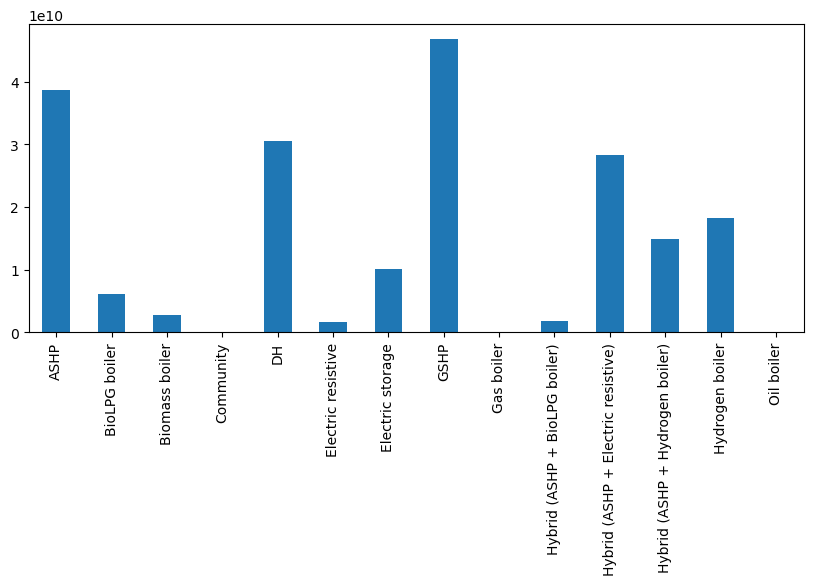

In [18]:
scaled_profiles_df.groupby(level=1, axis=1).sum().sum().plot.bar(figsize=(10,4))

In [19]:
scaled_profiles_df.groupby(level=1, axis=1).sum().sum().sum() / 1000000000

C:\Users\s2583817\AppData\Local\Temp\ipykernel_20608\4034920851.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  scaled_profiles_df.groupby(level=1, axis=1).sum().sum().sum() / 1000000000


200.19301174847837

In [20]:
# calculates the electric demand given the heat demand and the COPs
ed_hd_grid_sqs = ed.electric_demand_for_heat(scaled_profiles_dict, grid_sqs, df_ASHP, df_GSHP)

In [21]:

# Assume ed_hd_grid_sqs is your electric demand dictionary
# Define folder for saving
folder = r"data\LA_UK\new_version\outputs\elec_for_heat_demand_profiles"
os.makedirs(folder, exist_ok=True)

# Check if there's only one grid_id
if len(ed_hd_grid_sqs) == 1:
    grid_id = list(ed_hd_grid_sqs.keys())[0]
    df_kwh = ed_hd_grid_sqs[grid_id]  # already in kWh if not divided
    file_name = f"({grid_id})_{FES_scenario}_{FES_year}_{weather_year}_{future_year}_elec.csv"
    file_path = os.path.join(folder, file_name)
    df_kwh.to_csv(file_path)
    print(f"✅ Saved single-grid electric demand to: {file_path}")
else:
    # Multiple grid IDs: combine and save
    reformed_dict = {}
    for outerKey, innerDict in ed_hd_grid_sqs.items():
        for innerKey, values in innerDict.items():
            reformed_dict[(outerKey, innerKey)] = values

    df = pd.DataFrame.from_dict(reformed_dict) / 1e9  # GWh/TWh if needed
    df_kwh = df * 1e9  # back to kWh if saving as raw

    # Save combined data
    file_name = f"(ALL)_{FES_scenario}_{FES_year}_{weather_year}_{future_year}_elec.csv"
    file_path = os.path.join(folder, file_name)
    df_kwh.to_csv(file_path)
    print(f"✅ Saved multi-grid electric demand to: {file_path}")



✅ Saved multi-grid electric demand to: data\LA_UK\new_version\outputs\elec_for_heat_demand_profiles\(ALL)_LW_2022_2012_2050_elec.csv


In [22]:
reformed_dict = {}
for outerKey, innerDict in ed_hd_grid_sqs.items():
    for innerKey, values in innerDict.items():
        reformed_dict[(outerKey,
                    innerKey)] = values
df = pd.DataFrame.from_dict(reformed_dict) / 1000000000
# compare this to 47.856 TWh for Leading the Way 2050 from FES22 building blocks DEM_BB004
round(df.sum().sum(), 1)

41.2

C:\Users\s2583817\AppData\Local\Temp\ipykernel_20608\330307356.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df.groupby(level=1, axis=1).sum().sum().plot.bar(figsize=(10,4))


<Axes: >

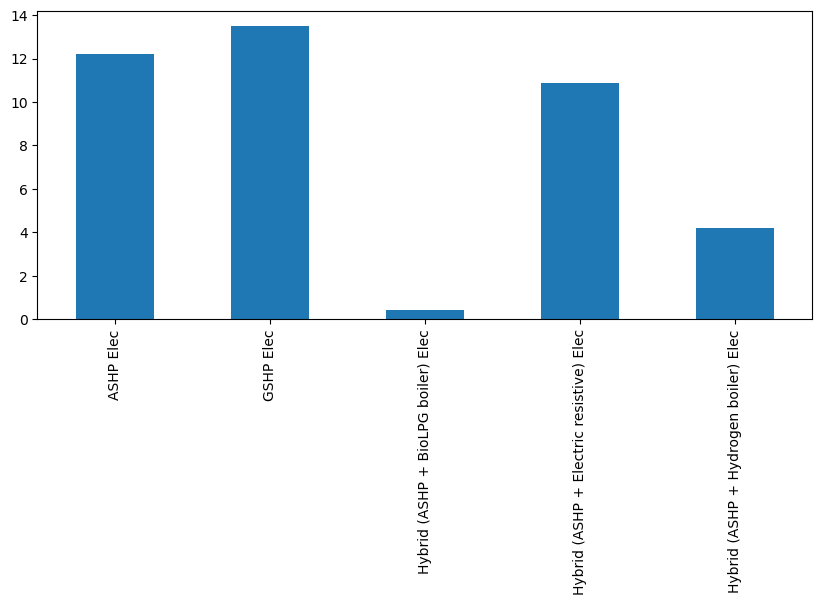

In [23]:
df.groupby(level=1, axis=1).sum().sum().plot.bar(figsize=(10,4))

In [24]:
df_4 = df.groupby(level=0, axis=1).sum()
df_4[df_4 < 0] = 0
df_4

C:\Users\s2583817\AppData\Local\Temp\ipykernel_20608\3879468526.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df_4 = df.groupby(level=0, axis=1).sum()


,-0.25_50.75,-0.25_51.0,-0.25_51.25,-0.25_51.5,-0.25_51.75,-0.25_52.0,-0.25_52.25,-0.25_52.5,-0.25_52.75,-0.25_53.0,...,1.5_51.25,1.5_51.5,1.5_52.0,1.5_52.25,1.5_52.5,1.5_52.75,1.5_53.0,1.75_52.25,1.75_52.5,1.75_52.75
2050-01-01 00:00:00,0.000004,0.000004,0.000010,0.000059,0.000008,0.000004,0.000002,0.000002,0.000001,0.000001,...,7.149463e-07,2.285583e-07,4.539863e-07,0.000001,0.000001,0.000001,1.757152e-08,1.286309e-07,0.000001,7.693260e-07
2050-01-01 00:30:00,0.000005,0.000004,0.000010,0.000061,0.000008,0.000004,0.000002,0.000002,0.000001,0.000001,...,7.368879e-07,2.355673e-07,4.679482e-07,0.000001,0.000001,0.000001,1.772706e-08,1.297662e-07,0.000001,7.760757e-07
2050-01-01 01:00:00,0.000005,0.000004,0.000011,0.000065,0.000008,0.000004,0.000002,0.000002,0.000002,0.000001,...,7.884089e-07,2.520351e-07,5.006821e-07,0.000002,0.000001,0.000001,1.841086e-08,1.347711e-07,0.000001,8.059896e-07
2050-01-01 01:30:00,0.000005,0.000004,0.000011,0.000068,0.000009,0.000004,0.000002,0.000002,0.000002,0.000001,...,8.227242e-07,2.630014e-07,5.224766e-07,0.000002,0.000001,0.000001,1.896874e-08,1.388552e-07,0.000001,8.304052e-07
2050-01-01 02:00:00,0.000006,0.000005,0.000013,0.000075,0.000009,0.000005,0.000002,0.000003,0.000002,0.000001,...,9.162208e-07,2.928776e-07,5.817911e-07,0.000002,0.000001,0.000001,2.048550e-08,1.499629e-07,0.000001,8.968590e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2050-12-31 21:30:00,0.000010,0.000009,0.000025,0.000152,0.000022,0.000011,0.000005,0.000006,0.000004,0.000003,...,1.653518e-06,5.007500e-07,1.068172e-06,0.000004,0.000004,0.000003,4.367944e-08,3.137877e-07,0.000003,1.961687e-06
2050-12-31 22:00:00,0.000008,0.000007,0.000021,0.000130,0.000019,0.000010,0.000004,0.000005,0.000003,0.000002,...,1.425293e-06,4.316581e-07,9.208710e-07,0.000003,0.000003,0.000003,3.745702e-08,2.691286e-07,0.000002,1.682109e-06
2050-12-31 22:30:00,0.000007,0.000006,0.000018,0.000109,0.000016,0.000008,0.000003,0.000005,0.000003,0.000002,...,1.200157e-06,3.634994e-07,7.755507e-07,0.000003,0.000003,0.000002,3.129159e-08,2.248819e-07,0.000002,1.405081e-06
2050-12-31 23:00:00,0.000006,0.000005,0.000015,0.000092,0.000014,0.000007,0.000003,0.000004,0.000002,0.000002,...,1.035844e-06,3.137549e-07,6.694900e-07,0.000002,0.000002,0.000002,2.664995e-08,1.915720e-07,0.000002,1.196516e-06


<Axes: >




In [25]:
df_4.plot.area(figsize=(20,8), cmap='tab20')

In [26]:
df_kwh = df * 1000000000
file_name = f"({grid_id})_{FES_scenario}_{FES_year}_{weather_year}_{future_year}_{'elec'}.csv"

folder = r"data\LA_UK\new_version\outputs\elec_for_heat_demand_profiles"
file_path = os.path.join(folder, file_name)
df_kwh.to_csv(file_path)